# CNN baselines for PatchVision: compact ResNets trained from scratch on CUB-200-2011

This notebook is the **CNN side of the study**. It trains two ResNet-style CNNs **from scratch** (no pretrained weights) and compares them with the Vision Transformer from `../ViT_PatchVisionX`.

| Experiment | Parameters | Purpose |
|---|---|---|
| `cnn_small` | about 4.2 M | **Matched to PatchVision-X (4.27 M).** The fair CNN-vs-ViT comparison. |
| `cnn_large` | about 11.3 M | ResNet-18 layout. What does more CNN capacity buy? (not parameter-matched) |

**Same conditions as the ViT `full` run:** same train/val/test split files, same normalisation, same `strong` augmentation, mixup/CutMix, label smoothing 0.1, AdamW (lr 5e-4, weight decay 0.05), 10 warm-up epochs then cosine decay, EMA weights, early stopping on validation (patience 60), best epoch chosen on **validation** only, test set used once at the end.
**Switched off for the CNN** (they need attention maps): bounding-box attention loss, flip-consistency loss, box-guided crop.

Everything is written to `CNN_Baseline/results/<experiment>/seed<seed>/` (same files as the ViT runs). A finished run is skipped; an interrupted run resumes.

**How to run:** start Jupyter inside the `CNN_Baseline/` folder. Keep `SMOKE_TEST = True` for the first pass (2 epochs on tiny synthetic data, a few minutes) to check that everything works, then set it to `False` and run all cells. Live progress from a terminal: `python watch_training.py cnn_small 42`.

In [1]:
import sys, json, time
from pathlib import Path

HERE = Path.cwd()
assert (HERE / "cnn").is_dir(), "Start Jupyter inside the CNN_Baseline/ folder (it must contain the cnn/ package)."
sys.path.insert(0, str(HERE))

import torch
import pandas as pd
from IPython.display import Image, Markdown, display

from cnn.config import PathsConfig, get_experiment, CNN_SUITE
from cnn.engine import run_experiment
from cnn.experiment import dry_run
from cnn.compare import default_entries, comparison_table, plot_comparison, plot_per_class_scatter
from patchvision.data import make_synthetic_dataset

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only (training would be very slow)")

torch 2.11.0+cu128 | CUDA available: True | NVIDIA GeForce RTX 5090


## 1. Settings

In [2]:
# ================================ USER SETTINGS ================================
SMOKE_TEST       = False                          # True: 2 epochs on synthetic data to test the pipeline. Set False for the real runs.
EXPERIMENTS      = ["cnn_small", "cnn_large"]     # any keys of CNN_SUITE. Run "cnn_small" first if you want to check it before the big one.
SEEDS            = [42]                           # use [42, 43, 44] for mean +/- std over seeds
NUM_WORKERS      = 6                              # data-loading processes (use 0 if you ever hit a multiprocessing error on Windows)
STEP_PRINT_EVERY = 21                             # 1 = print EVERY training step (the log file always has every step)
RESUME           = True                           # continue from last.pt if a run was interrupted

MODEL_OVERRIDES  = {}                             # e.g. {"widths": (48, 96, 192, 384)}
TRAIN_OVERRIDES  = {}                             # e.g. {"epochs": 200, "lr": 1e-3, "early_stop_patience": 40}
# ===============================================================================

PATHS = PathsConfig(root="..", results_dir="CNN_Baseline/results")   # shared data one level up; results stay in this folder
if SMOKE_TEST:
    PATHS = make_synthetic_dataset("smoke_data", n_classes=8, n_train=12, n_val=2, n_test=4)
    TRAIN_OVERRIDES = dict(epochs=2, warmup_epochs=1, batch_size=16, snapshot_every=1, clean_eval_every=1,
                           clean_eval_size=16, early_stop_patience=0, weights_every=0)
    NUM_WORKERS = min(NUM_WORKERS, 2)
    print(">>> SMOKE TEST: synthetic data in ./smoke_data, 2 epochs <<<")
print("experiments available:", list(CNN_SUITE))
print("results will be written to:", PATHS.results)

experiments available: ['cnn_small', 'cnn_large']
results will be written to: C:\Samruddhi\patchvision-vit-cub200\CNN_Baseline\results


## 2. Model sizes: are the CNN and the ViT comparable?
`cnn_small` is sized to match PatchVision-X's parameter count. (FLOPs and latency are measured on the real runs below.)

In [3]:
from cnn.model import build_model
from patchvision.utils import count_parameters

rows = []
for n in CNN_SUITE:
    e = get_experiment(n)
    rows.append({"model": n, "stage widths": e.model.widths, "blocks per stage": e.model.blocks,
                 "parameters (M)": round(count_parameters(build_model(e.model))[0] / 1e6, 3)})
rows.append({"model": "PatchVision-X (ViT, reference)", "stage widths": "-", "blocks per stage": "-", "parameters (M)": 4.273})
display(pd.DataFrame(rows))

,model,stage widths,blocks per stage,parameters (M)
0,cnn_small,"(39, 78, 156, 312)","(2, 2, 2, 2)",4.217
1,cnn_large,"(64, 128, 256, 512)","(2, 2, 2, 2)",11.279
2,"PatchVision-X (ViT, reference)",-,-,4.273


## 3. Dry run: one real batch through forward and backward
Checks the output shape, that the starting loss is close to ln(200) = 5.30 (a model that knows nothing), and that every parameter gets a finite gradient.

In [4]:
for name in EXPERIMENTS:
    dry_run(get_experiment(name, SEEDS[0], MODEL_OVERRIDES, TRAIN_OVERRIDES), PATHS)
    print()

W1030 19:53:26.655000 42828 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


cnn_small: 4.22 M parameters | GFLOPs 1.40 | latency bs1 3.6 ms


batch: images (64, 3, 224, 224) | x mean/std -0.23/1.10


logits (64, 200) | loss 5.3924 (chance ln(200) = 5.2983) | params without finite grad: none [OK]

cnn_large: 11.28 M parameters | GFLOPs 3.63 | latency bs1 1.6 ms


batch: images (64, 3, 224, 224) | x mean/std -0.24/1.07
logits (64, 200) | loss 5.3673 (chance ln(200) = 5.2983) | params without finite grad: none [OK]



## 4. Train
Each run writes `train_log.txt` (every step), `history.csv` (every epoch), `curves.png`, checkpoints, and at the end the test results. The best epoch is chosen on the **validation** photos; the **test** photos are only used once, at the end.

In [5]:
results = []
for name in EXPERIMENTS:
    for seed in SEEDS:
        exp = get_experiment(name, seed, MODEL_OVERRIDES, TRAIN_OVERRIDES)
        t0 = time.time()
        row = run_experiment(exp, PATHS, num_workers=NUM_WORKERS, step_print_every=STEP_PRINT_EVERY, resume=RESUME)
        results.append(row)
        print(f"\n>>> {name} seed {seed}: test top-1 {row['test_acc1']:.2f}% | top-5 {row['test_acc5']:.2f}% | "
              f"macro-F1 {row['test_macro_f1']:.2f}% | best epoch {row['best_epoch']} | {(time.time() - t0) / 60:.1f} min this session\n")
display(pd.DataFrame(results)[["experiment", "seed", "best_epoch", "epochs_run", "test_acc1", "test_acc5", "test_macro_f1", "test_ece", "params_M", "GFLOPs"]].round(2))

[cnn_small | seed 42] already finished -> loading C:\Samruddhi\patchvision-vit-cub200\CNN_Baseline\results\cnn_small\seed42\test_metrics.json

>>> cnn_small seed 42: test top-1 43.65% | top-5 69.02% | macro-F1 43.54% | best epoch 163 | 0.0 min this session

[cnn_large | seed 42] already finished -> loading C:\Samruddhi\patchvision-vit-cub200\CNN_Baseline\results\cnn_large\seed42\test_metrics.json

>>> cnn_large seed 42: test top-1 45.86% | top-5 71.16% | macro-F1 45.79% | best epoch 140 | 0.0 min this session



,experiment,seed,best_epoch,epochs_run,test_acc1,test_acc5,test_macro_f1,test_ece,params_M,GFLOPs
0,cnn_small,42,163,223,43.65,69.02,43.54,7.07,4.22,1.40
1,cnn_large,42,140,200,45.86,71.16,45.79,8.56,11.28,3.63


## 5. Results of the CNN runs
Training curves, confusion matrix and calibration for every finished run. (Skipped in smoke-test mode.)

### cnn_small (seed 42)

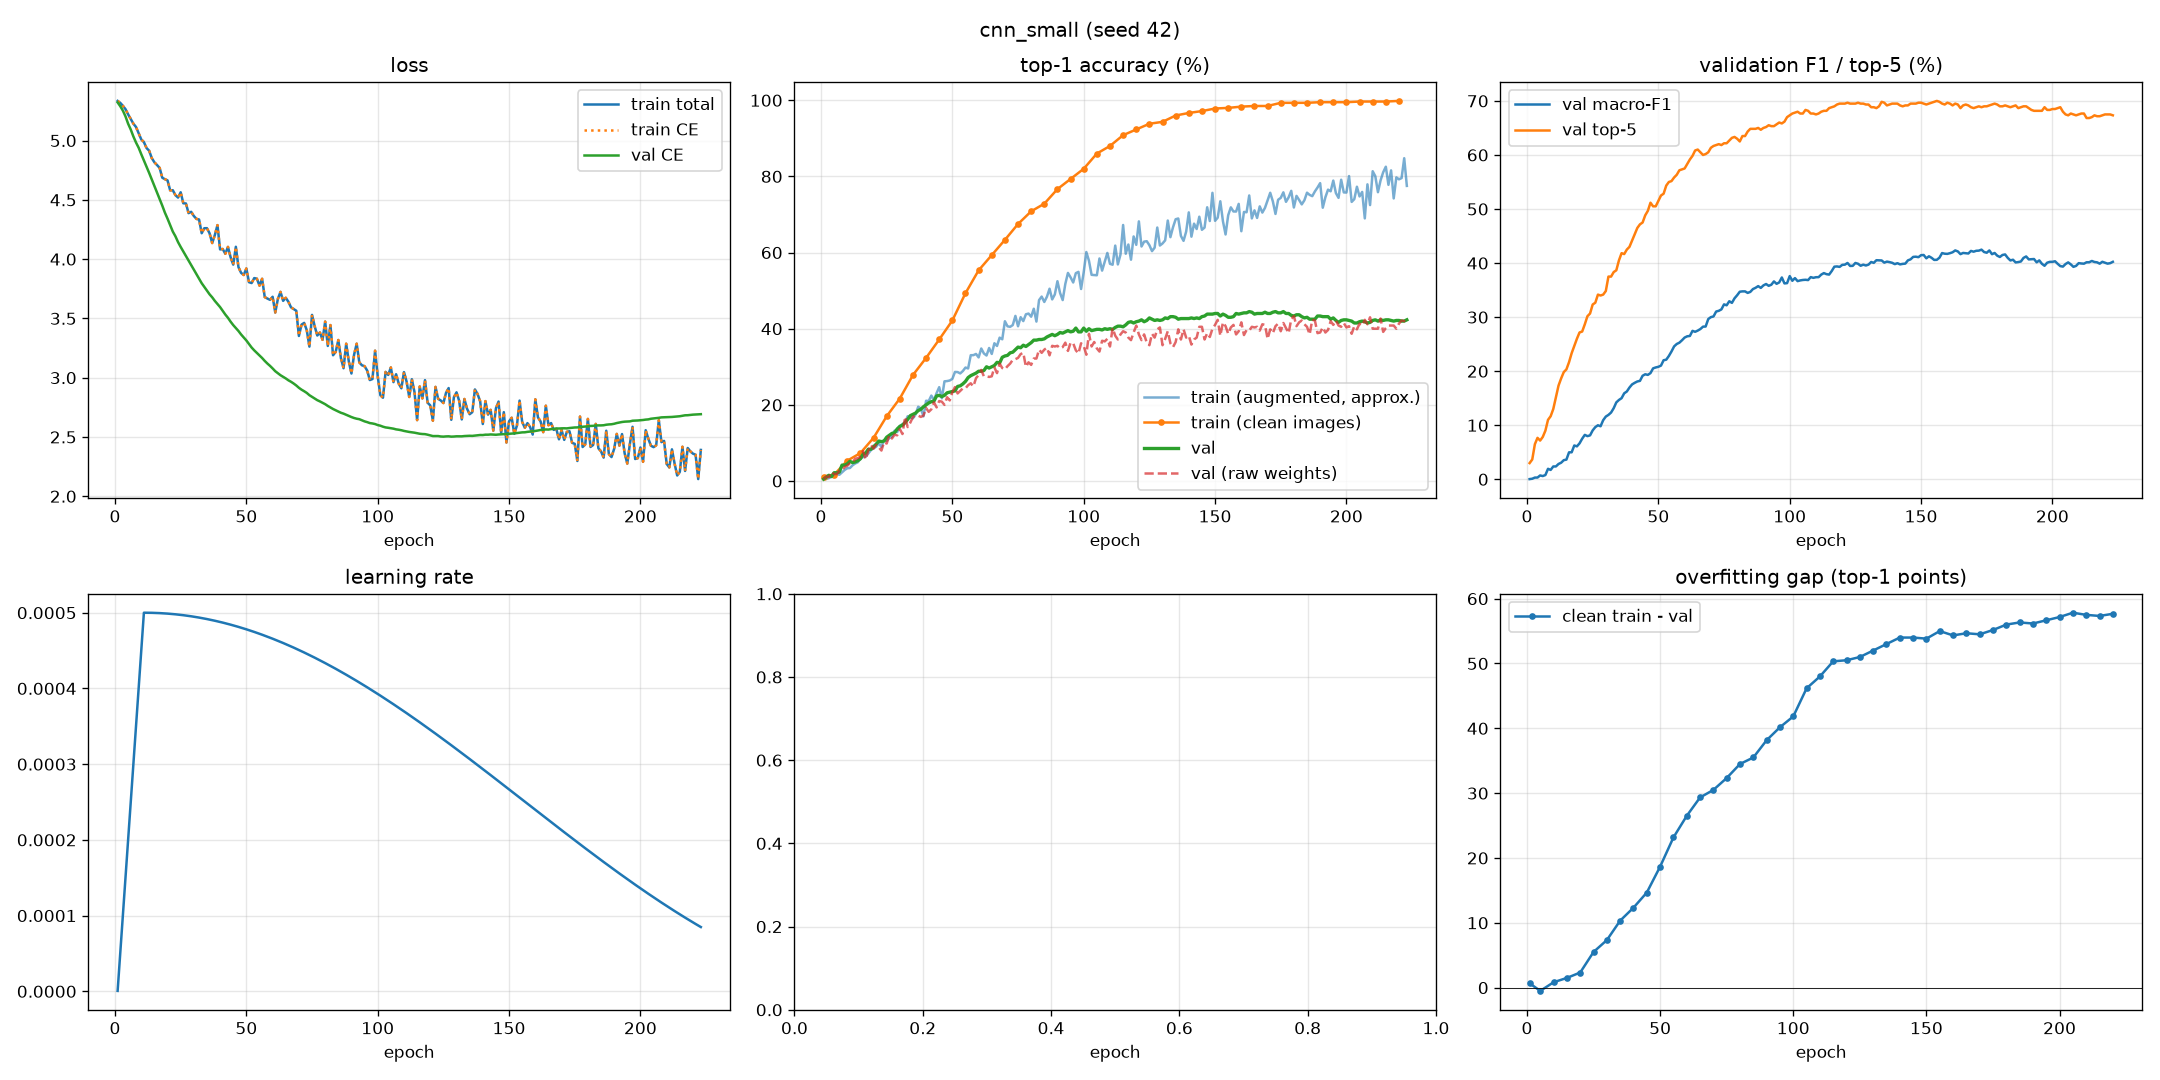

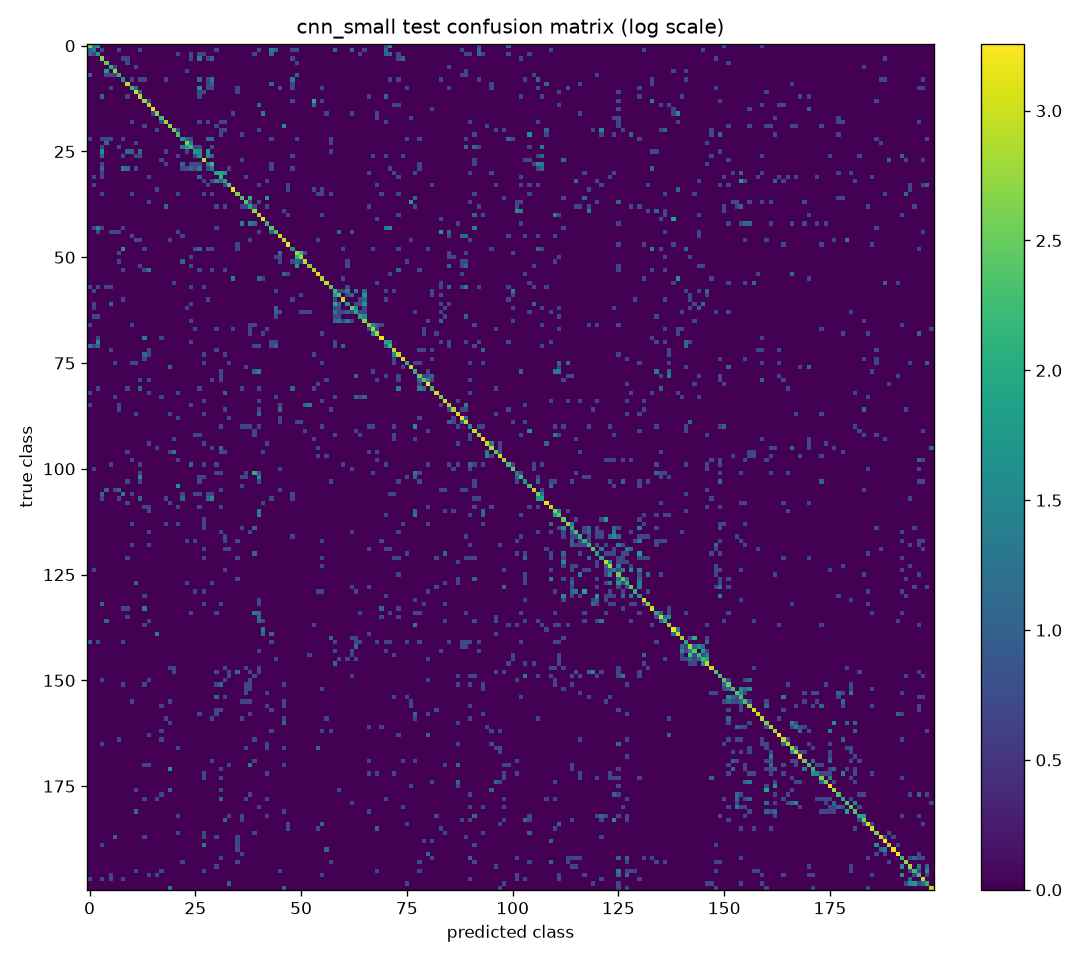

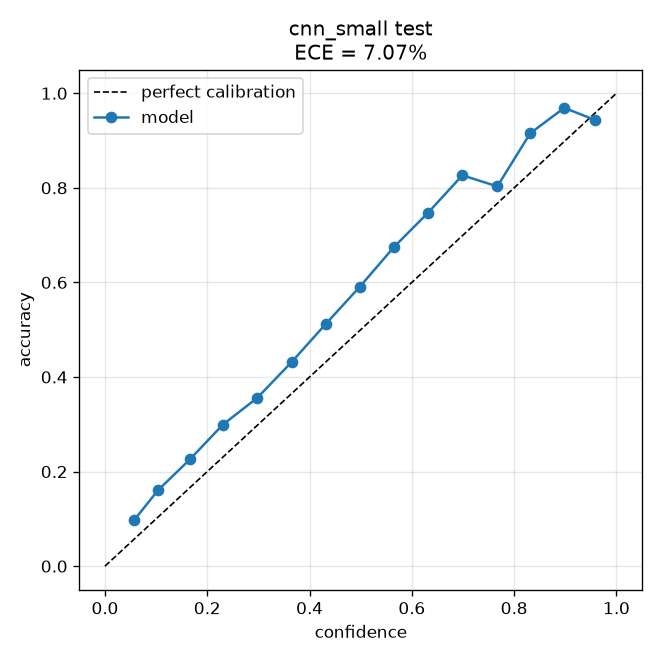

**Hardest 8 species (lowest F1)** and **easiest 8**

,class_name,precision,recall,f1,support
29,Fish Crow,7.9,10.0,8.8,30
124,Lincoln Sparrow,10.0,10.3,10.2,29
28,American Crow,11.5,10.0,10.7,30
130,Vesper Sparrow,9.1,13.3,10.8,30
101,Western Wood Pewee,14.3,10.0,11.8,30
26,Shiny Cowbird,10.5,13.3,11.8,30
1,Laysan Albatross,17.6,10.0,12.8,30
90,Mockingbird,12.9,13.3,13.1,30
188,Red bellied Woodpecker,69.4,83.3,75.8,30
69,Green Violetear,76.7,76.7,76.7,30


### cnn_large (seed 42)

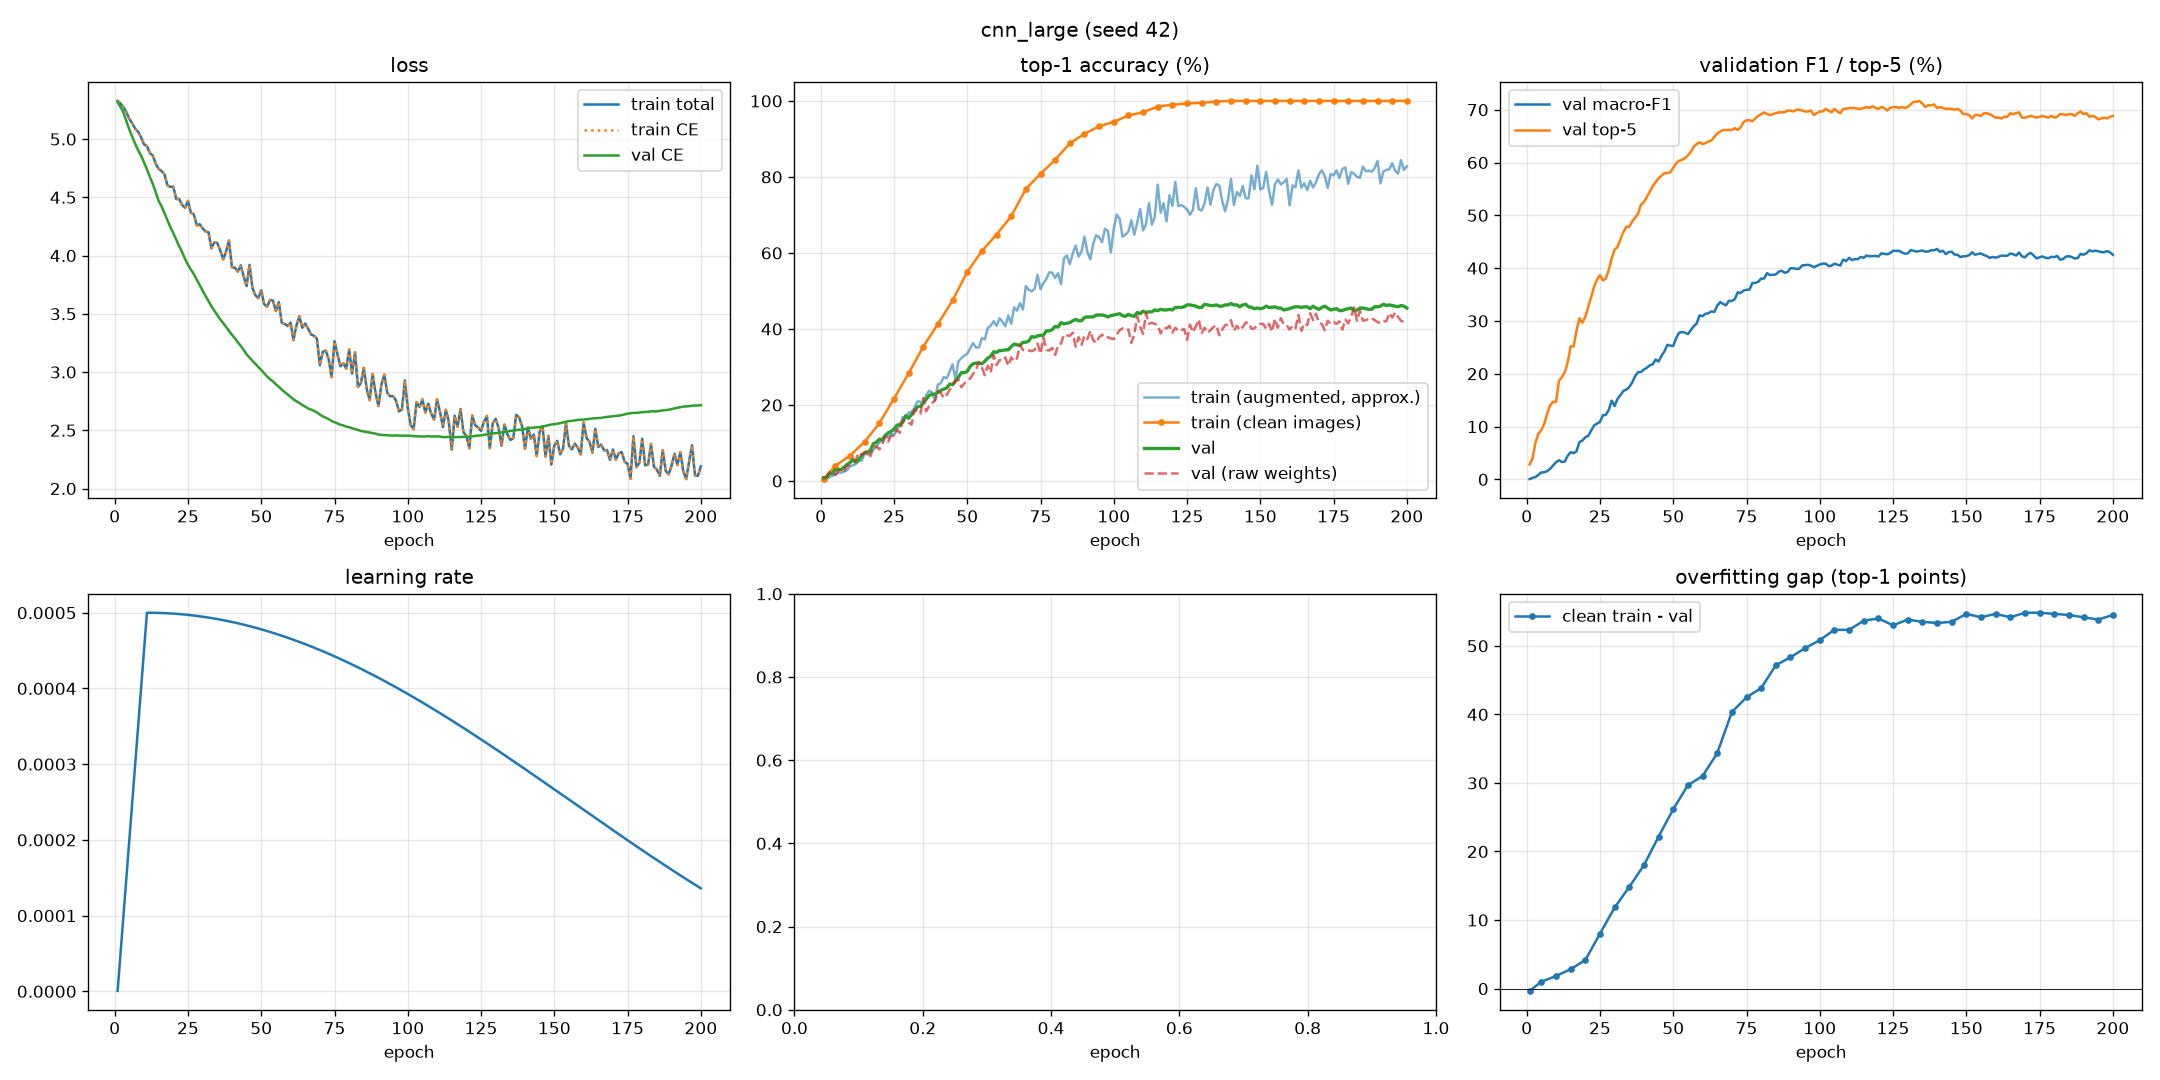

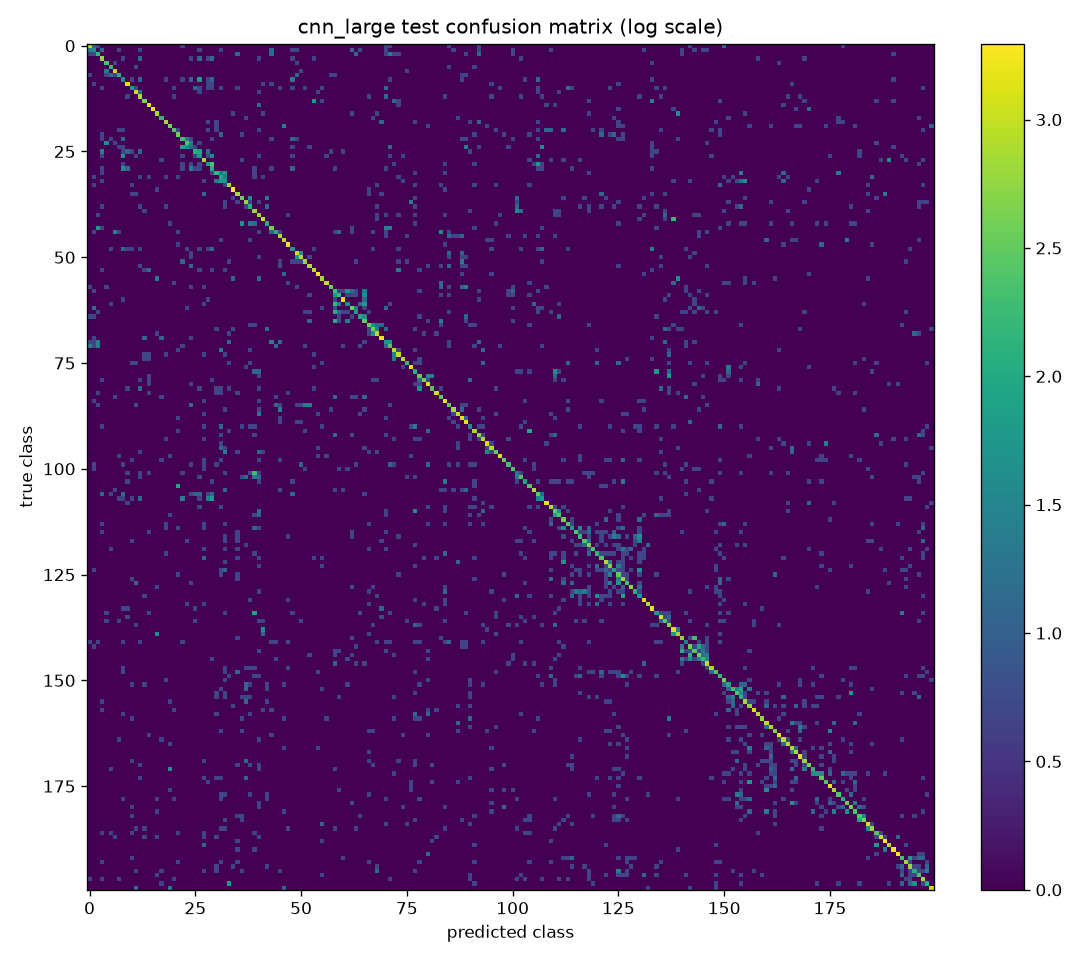

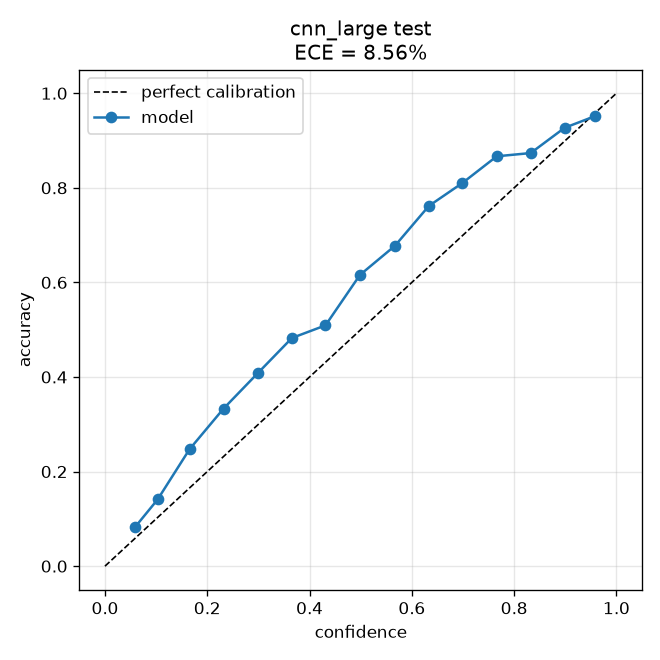

**Hardest 8 species (lowest F1)** and **easiest 8**

,class_name,precision,recall,f1,support
24,Pelagic Cormorant,8.0,6.7,7.3,30
101,Western Wood Pewee,12.5,10.0,11.1,30
141,Black Tern,15.8,10.0,12.2,30
8,Brewer Blackbird,12.5,13.8,13.1,29
90,Mockingbird,14.3,13.3,13.8,30
32,Yellow billed Cuckoo,11.9,17.2,14.1,29
130,Vesper Sparrow,13.5,16.7,14.9,30
1,Laysan Albatross,17.4,13.3,15.1,30
97,Scott Oriole,87.5,70.0,77.8,30
108,American Redstart,82.1,76.7,79.3,30


In [6]:
if SMOKE_TEST:
    print("Smoke test: the plots below are only meaningful for the real runs.")
else:
    for name in EXPERIMENTS:
        rd = PATHS.results / name / f"seed{SEEDS[0]}"
        if not (rd / "test_metrics.json").exists():
            print(f"{name}: not finished yet"); continue
        display(Markdown(f"### {name} (seed {SEEDS[0]})"))
        for f in ("curves.png", "test_confusion_matrix.png", "test_reliability.png"):
            display(Image(str(rd / f)))
        pc = pd.read_csv(rd / "test_per_class.csv").sort_values("f1")
        display(Markdown("**Hardest 8 species (lowest F1)** and **easiest 8**"))
        display(pd.concat([pc.head(8), pc.tail(8)])[["class_name", "precision", "recall", "f1", "support"]].round(1))

## 6. CNN vs ViT: the comparison
Reads the finished runs of **both** studies: `CNN_Baseline/results/` and `ViT_PatchVisionX/results/`. The ViT `base` row is the stripped-down transformer, `PatchVision-X (full)` is the complete model. All numbers are on the same 5,794 test photos.

In [7]:
if SMOKE_TEST:
    print("Smoke test: nothing to compare. Set SMOKE_TEST = False and run the real experiments first.")
else:
    ENTRIES = default_entries(PATHS.root_path, seed=SEEDS[0])
    table = comparison_table(ENTRIES)
    display(table.round(2))
    table.round(3).to_csv(PATHS.results / "comparison_table.csv")
    print("saved:", PATHS.results / "comparison_table.csv")

,params (M),GFLOPs,top-1 (%),top-5 (%),macro-F1 (%),ECE (%),train-val gap (pts),best epoch,epochs run,train time (min),s / epoch,latency bs1 (ms)
model,,,,,,,,,,,,
CNN small (4.2M),4.22,1.40,43.65,69.02,43.54,7.07,54.67,163,223,33.55,9.03,1.55
CNN large (11.3M),11.28,3.63,45.86,71.16,45.79,8.56,53.33,140,200,29.98,8.99,1.95
ViT base,4.31,1.55,39.52,65.12,39.12,2.49,59.83,186,246,48.42,11.81,12.83
PatchVision-X (full),4.27,1.55,47.39,73.59,47.05,5.95,49.83,153,213,71.20,20.06,15.01


saved: C:\Samruddhi\patchvision-vit-cub200\CNN_Baseline\results\comparison_table.csv


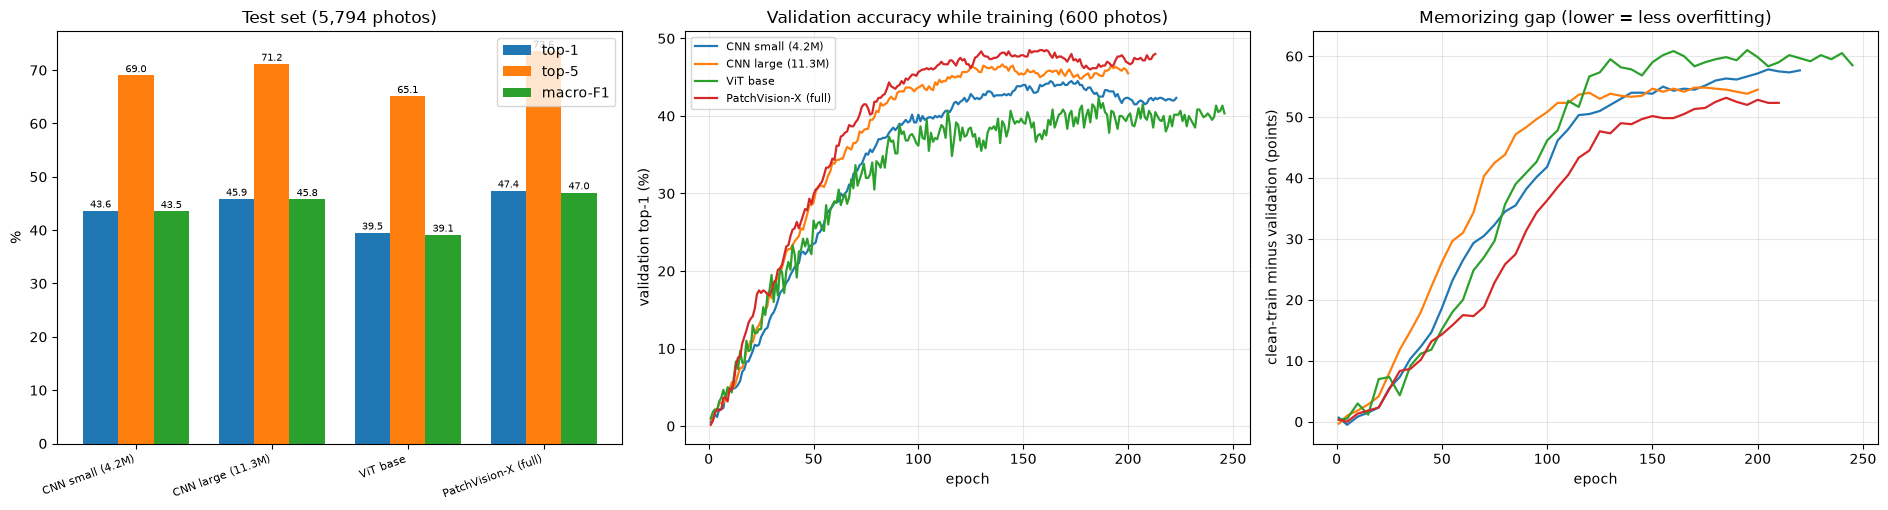

In [8]:
if not SMOKE_TEST:
    plot_comparison(ENTRIES, path=PATHS.results / "comparison.png", show=True)

### Species by species: where does each model win?
Each dot is one bird species. Dots above the dashed line are species where the second model has the higher F1.

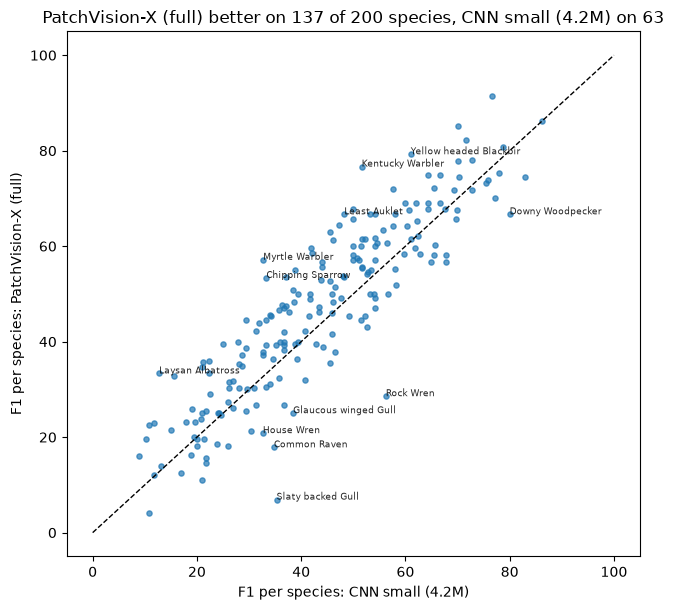

**Species where CNN small (4.2M) is clearly better**

,a,b,diff
class_name,,,
Slaty backed Gull,35.3,6.9,-28.4
Rock Wren,56.2,28.6,-27.7
Common Raven,34.8,17.9,-16.9
Glaucous winged Gull,38.5,25.0,-13.5
Downy Woodpecker,80.0,66.7,-13.3
House Wren,32.7,20.8,-11.8
Bohemian Waxwing,67.8,56.7,-11.1
Northern Flicker,45.6,35.6,-10.1


**Species where PatchVision-X (full) is clearly better**

,a,b,diff
class_name,,,
White throated Sparrow,50.0,67.9,17.9
Yellow throated Vireo,41.8,59.6,17.9
Yellow headed Blackbird,61.0,79.2,18.2
Least Auklet,48.3,66.7,18.4
Chipping Sparrow,33.3,53.3,20.0
Laysan Albatross,12.8,33.3,20.6
Myrtle Warbler,32.7,57.1,24.4
Kentucky Warbler,51.6,76.7,25.1


In [9]:
if not SMOKE_TEST:
    E = dict(ENTRIES)
    a, b = "CNN small (4.2M)", "PatchVision-X (full)"
    if a in E and b in E:
        d = plot_per_class_scatter((a, E[a]), (b, E[b]), path=PATHS.results / "per_class_cnn_vs_vit.png", show=True)
        display(Markdown(f"**Species where {a} is clearly better**"))
        display(d.head(8).round(1))
        display(Markdown(f"**Species where {b} is clearly better**"))
        display(d.tail(8).round(1))
    else:
        print("Need both", a, "and", b, "to be finished.")

### Several seeds: mean and standard deviation
Only meaningful when `SEEDS` has more than one value (the final report needs at least three, for the CNN and for the ViT).

In [10]:
if not SMOKE_TEST:
    rows = []
    for name in EXPERIMENTS:
        for seed in SEEDS:
            f = PATHS.results / name / f"seed{seed}" / "test_metrics.json"
            if f.exists():
                rows.append(json.loads(f.read_text())["row"])
    if rows:
        df = pd.DataFrame(rows)
        agg = df.groupby("experiment")[["test_acc1", "test_acc5", "test_macro_f1", "test_ece"]].agg(["mean", "std", "count"]).round(2)
        display(agg)

test_acc1           test_acc5           test_macro_f1           test_ece          
                mean std count      mean std count          mean std count     mean std count
experiment                                                                                   
cnn_large      45.86 NaN     1     71.16 NaN     1         45.79 NaN     1     8.56 NaN     1
cnn_small      43.65 NaN     1     69.02 NaN     1         43.54 NaN     1     7.07 NaN     1

## 7. Conclusions (fill in after the real runs)
Write these from the table and figures above, not from expectation:

1. **Does the matched CNN (`cnn_small`) beat PatchVision-X?** By how many points in top-1 / macro-F1, and is that difference larger than the sampling noise (about plus/minus 1.3 points on 5,794 test photos) and the seed-to-seed spread?
2. **What does extra CNN capacity buy** (`cnn_large` vs `cnn_small`)? Does the gap to the ViT change?
3. **Memorizing gap:** which model overfits less (train-val gap column)? Is the ViT's gap of about 50 points a transformer problem or a small-data problem?
4. **Cost:** parameters, GFLOPs, latency and training time per model.
5. **Where do they differ per species?** (scatter plot above)
6. **Limits of this study:** one seed unless more were run; the ViT `full` model uses extra training signals (bird boxes) that the CNN does not; the CNN uses the ViT's learning rate and weight decay without being tuned for it.